# code_088 · Bagging random forests and extra trees

**Book:** section 18.2. A self-contained trees-and-ensembles laboratory with generated records, explicit source assumptions and preserved provenance. Prerequisites: Python arrays/tables and Chapter 8's information contracts. Restart and run all cells. Imports, helpers and inputs are internal; ordinary execution needs no files, network, credentials, GPU or private module. Use the [quickstart](../README.md), [pinned environment](../requirements-lock.txt), [guide](../CHAPTER_18_GUIDE.md), [run evidence](../CHAPTER_18_EXECUTION.md) and [registry](../CODE_EXAMPLES.md#code_088).

Reference: CPython 3.14.3, NumPy 2.4.4, SciPy 1.17.1, pandas 3.0.3, Matplotlib 3.11.0, scikit-learn 1.9.0, CPU. Allow a minute to execute and 30–60 minutes to interpret. These scoped experiments expose task/data and fixed fitting controls rather than claim exhaustive estimator API coverage. Splits, fitted transformations, model selection and assessment declare their evidence boundaries locally. Synthetic cohort sizes and prevalences are constructed rather than population estimates. All numerical data are generated. These comparisons expose structural assumptions, information boundaries and transformation contracts without field-validity, causal or universal physical-model claims.


In [1]:
import platform,time,json
import numpy as np
import scipy,pandas as pd,matplotlib,matplotlib.pyplot as plt,sklearn
from IPython.display import display
import threadpoolctl
_THREAD_LIMIT=threadpoolctl.threadpool_limits(1)
START=time.perf_counter();SEED=1888;rng=np.random.default_rng(SEED)
VERSIONS={'python':platform.python_version(),'numpy':np.__version__,'scipy':scipy.__version__,'pandas':pd.__version__,'matplotlib':matplotlib.__version__,'scikit-learn':sklearn.__version__,'threadpoolctl':threadpoolctl.__version__}
print(VERSIONS);print('CPU:',platform.system(),platform.machine(),'seed:',SEED)
plt.rcParams.update({'figure.dpi':110,'font.size':11,'axes.titlesize':9,'axes.spines.top':False,'axes.spines.right':False,'figure.constrained_layout.use':True})
RESULTS={}


{'python': '3.14.3', 'numpy': '2.4.4', 'scipy': '1.17.1', 'pandas': '3.0.3', 'matplotlib': '3.11.0', 'scikit-learn': '1.9.0', 'threadpoolctl': '3.7.0'}
CPU: Darwin arm64 seed: 1888


<a id="forests"></a>
## Average varied fits, then check what varied

Generate training240/development120/final240 independent member records with six descriptors, first two correlated measurements (second=first+NormalSD.03), response sin4x0+.6*x2+noiseSD.3. Compare a fixed deep tree, bootstrap bagging of deep trees, random forest using half the features per split, and ExtraTrees using randomized thresholds/no bootstrap. All ensembles use80trees/minleaf2, no development tuning; development is a diagnostic cohort. Direct tree predictions must average to the bagged prediction. Bootstrap tree disagreement is a sensitivity diagnostic, not a confidence interval. Shared structure or measurement error can remain after averaging.


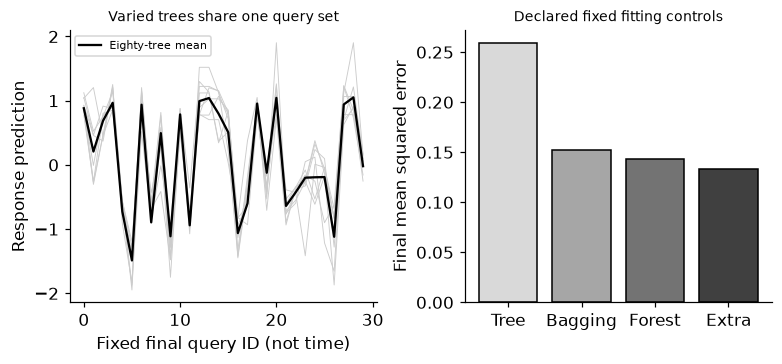

In [2]:
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import BaggingRegressor,RandomForestRegressor,ExtraTreesRegressor
from sklearn.metrics import mean_squared_error
def generate(n):
 a=rng.uniform(-1,1,(n,6));a[:,1]=a[:,0]+rng.normal(0,.03,n);b=np.sin(4*a[:,0])+.6*a[:,2]+rng.normal(0,.3,n);return a,b
X,y=generate(240);Xd,yd=generate(120);Xt,yt=generate(240);base=DecisionTreeRegressor(min_samples_leaf=2,random_state=SEED);bag=BaggingRegressor(estimator=base,n_estimators=80,bootstrap=True,random_state=SEED,n_jobs=1,oob_score=True);rf=RandomForestRegressor(n_estimators=80,min_samples_leaf=2,max_features=.5,bootstrap=True,oob_score=True,random_state=SEED,n_jobs=1);extra=ExtraTreesRegressor(n_estimators=80,min_samples_leaf=2,max_features=.5,bootstrap=False,random_state=SEED,n_jobs=1);fits={name:fit.fit(X,y) for name,fit in [('Single tree',base),('Bagging',bag),('Random forest',rf),('Extra trees',extra)]};rows=[]
for name,fit in fits.items():rows.append({'model':name,'development_mse':float(mean_squared_error(yd,fit.predict(Xd))),'final_mse':float(mean_squared_error(yt,fit.predict(Xt))),'trees':1 if name=='Single tree' else 80})
individual=np.array([tree.predict(Xt[:,cols]) for tree,cols in zip(bag.estimators_,bag.estimators_features_)]);np.testing.assert_allclose(individual.mean(axis=0),bag.predict(Xt),atol=1e-12);centered=individual-individual.mean(axis=1,keepdims=True);corr=np.corrcoef(centered);mean_corr=float(corr[np.triu_indices(80,1)].mean());assert np.isfinite(mean_corr)
# Across independent fitting resamples, compare one-tree versus averaged predictions at the same queries.
rep_single=[];rep_bag=[]
for seed in range(SEED,SEED+24):
 ix=np.random.default_rng(seed).choice(len(y),len(y),replace=True);t=DecisionTreeRegressor(min_samples_leaf=2,random_state=seed).fit(X[ix],y[ix]);b=BaggingRegressor(estimator=DecisionTreeRegressor(min_samples_leaf=2),n_estimators=30,random_state=seed,n_jobs=1).fit(X[ix],y[ix]);rep_single.append(t.predict(Xt));rep_bag.append(b.predict(Xt))
RESULTS['independent_members']={'roles':{'training':240,'development_diagnostic_only':120,'final':240},'first_two_training_correlation':float(np.corrcoef(X[:,:2].T)[0,1]),'fixed_candidates':rows,'within_bag_mean_pair_prediction_correlation':mean_corr,'refit_resamples':24,'single_mean_prediction_variance':float(np.var(rep_single,axis=0,ddof=1).mean()),'bag30_mean_prediction_variance':float(np.var(rep_bag,axis=0,ddof=1).mean()),'bag80_OOB_mse':float(mean_squared_error(y,bag.oob_prediction_)),'rf80_OOB_mse':float(mean_squared_error(y,rf.oob_prediction_))}
fig,axes=plt.subplots(1,2,figsize=(7,3.2));q=np.arange(30)
for pred in individual[:8]:axes[0].plot(q,pred[:30],color='.8',lw=.6)
axes[0].plot(q,bag.predict(Xt[:30]),color='black',lw=1.5,label='Eighty-tree mean');axes[0].set(xlabel='Fixed final query ID (not time)',ylabel='Response prediction',title='Varied trees share one query set');axes[0].legend(fontsize=7);axes[1].bar(range(4),[r['final_mse'] for r in rows],color=['.85','.65','.45','.25'],edgecolor='black');axes[1].set(xticks=range(4),xticklabels=['Tree','Bagging','Forest','Extra'],ylabel='Final mean squared error',title='Declared fixed fitting controls');plt.show()


<a id="oob"></a>
## A row can be out of bag while its building remains in memory

A separate deliberately dependent fixture has thirty buildings, eight repeated records each. An asset coordinate uniquely identifies the building and a constant random binary label is shared by all its rows. A bootstrap80tree forest leaves individual rows out, but sibling rows from the same building usually remain. Twenty entirely new buildings have independently assigned labels. Compare OOB accuracy with new-building accuracy; the fixture exposes an invalid entity claim, not realistic failure physics. Report the empirical frequency with which an omitted row still has a sibling in a tree's fitting sample. OOB estimates remain useful for their actual row-resampling question, not automatically for unseen buildings.


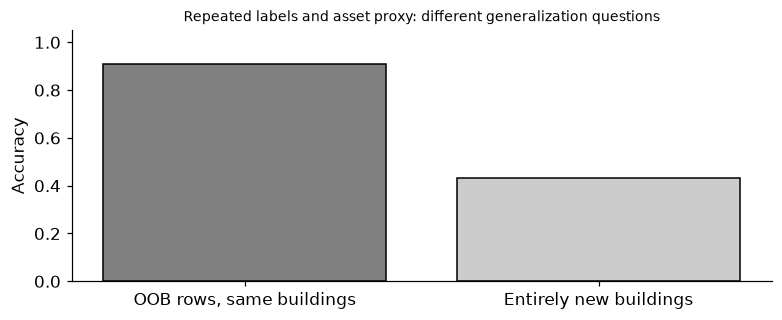

In [3]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
building=np.repeat(np.arange(30),8);asset_values=np.arange(30)*10.;labels=rng.integers(0,2,30);gx=np.column_stack([asset_values[building],rng.normal(size=len(building))*.001]);gy=labels[building];forest=RandomForestClassifier(n_estimators=80,random_state=SEED,n_jobs=1,oob_score=True).fit(gx,gy);new_asset=np.arange(30,50)*10.;new_x=np.column_stack([np.repeat(new_asset,8),rng.normal(size=160)*.001]);new_y=np.repeat(rng.integers(0,2,20),8);siblings=eligible=0
for samples in forest.estimators_samples_:
 used=np.zeros(len(gy),bool);used[samples]=True
 for ix in np.flatnonzero(~used):eligible+=1;siblings+=bool(np.any(used&(building==building[ix])))
assert eligible>0 and siblings<=eligible;assert np.isfinite(forest.oob_decision_function_).all();RESULTS['dependent_OOB_fixture']={'training_buildings':30,'rows_per_building':8,'new_buildings':20,'OOB_accuracy':float(forest.oob_score_),'new_building_accuracy':float(accuracy_score(new_y,forest.predict(new_x))),'omitted_row_tree_pairs':eligible,'fraction_with_training_sibling':siblings/eligible,'asset_coordinate_is_identity_proxy':True}
fig,ax=plt.subplots(figsize=(7,2.8));ax.bar([0,1],[forest.oob_score_,accuracy_score(new_y,forest.predict(new_x))],color=['.5','.8'],edgecolor='black');ax.set(xticks=[0,1],xticklabels=['OOB rows, same buildings','Entirely new buildings'],ylabel='Accuracy',ylim=(0,1.05),title='Repeated labels and asset proxy: different generalization questions');plt.show()


In [4]:
summary={'example_id':'code_088','seed':SEED,'versions':VERSIONS,'hardware':platform.system()+' '+platform.machine()+' CPU','concepts_demonstrated':['bootstrap and randomized threshold ensembles', 'prediction instability and covariance', 'out-of-bag rows versus new entities', 'correlated measurements and fixed held-out comparison'],'results':RESULTS,'elapsed_seconds':round(time.perf_counter()-START,3)}
print('EXECUTION_SUMMARY_JSON:'+json.dumps(summary,sort_keys=True,allow_nan=False))


EXECUTION_SUMMARY_JSON:{"concepts_demonstrated": ["bootstrap and randomized threshold ensembles", "prediction instability and covariance", "out-of-bag rows versus new entities", "correlated measurements and fixed held-out comparison"], "elapsed_seconds": 0.989, "example_id": "code_088", "hardware": "Darwin arm64 CPU", "results": {"dependent_OOB_fixture": {"OOB_accuracy": 0.9083333333333333, "asset_coordinate_is_identity_proxy": true, "fraction_with_training_sibling": 1.0, "new_building_accuracy": 0.43125, "new_buildings": 20, "omitted_row_tree_pairs": 7050, "rows_per_building": 8, "training_buildings": 30}, "independent_members": {"bag30_mean_prediction_variance": 0.024668298292780808, "bag80_OOB_mse": 0.15617369358527905, "first_two_training_correlation": 0.9986751159995971, "fixed_candidates": [{"development_mse": 0.16497594492100195, "final_mse": 0.25881026845530947, "model": "Single tree", "trees": 1}, {"development_mse": 0.11920647450341286, "final_mse": 0.15221978813114614, "mode